# 04 - LLM Fine-Tuning Comparison: Base vs QLoRA Fine-Tuned

Compares a **base instruction-tuned LLM** against the **QLoRA fine-tuned** checkpoint (`src/llm/finetuning.py`) on the customer support SFT dataset, using Exact Match, ROUGE-L, format compliance and (optionally) BERTScore.

**Important:** actually running `Qwen/Qwen2.5-3B-Instruct` (base and fine-tuned) requires a GPU with the `transformers`/`peft`/`bitsandbytes` stack installed -- not available in this notebook's execution environment. This notebook is fully wired to run for real once you have:

1. Trained an adapter with `python -m src.llm.finetuning --base-model Qwen/Qwen2.5-3B-Instruct --data data/sample/sft_dataset.json --output checkpoints/qlora-support-assistant`
2. A CUDA GPU available in the kernel.

Until then, it demonstrates the **evaluation methodology** with template-based mock generations (`heuristic_generate`, the same deterministic fallback used by the RAG pipeline/API when no GPU LLM is configured) standing in for 'base model' vs a perfect-match stand-in for 'fine-tuned model', so the metric computation and comparison table are exercised end-to-end.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))

from src.llm.evaluation import evaluate_generations
from src.rag.generation import heuristic_generate

In [2]:
ROOT = Path.cwd().parent
sft_examples = json.loads((ROOT / 'data/sample/sft_dataset.json').read_text())
pd.DataFrame(sft_examples)[['query', 'response']]

,query,response
0,I was charged twice for my Premium subscription.,"{""intent"": ""billing_issue"", ""priority"": ""high""..."
1,How do I request a refund for my annual plan?,"{""intent"": ""refund_request"", ""priority"": ""medi..."
2,How can I cancel my subscription before renewal?,"{""intent"": ""cancellation"", ""priority"": ""low"", ..."
3,My credit card payment keeps failing.,"{""intent"": ""payment_issue"", ""priority"": ""mediu..."
4,This is the third time I've been billed incorr...,"{""intent"": ""billing_issue"", ""priority"": ""high""..."


## Generate with the 'base model' stand-in

`heuristic_generate` is a deterministic template -- a reasonable proxy for an un-fine-tuned instruction model that hasn't learned the project's exact JSON schema/tone yet.

In [3]:
import dataclasses

base_predictions = []
for ex in sft_examples:
    result = heuristic_generate(ex['query'], ex['context'], retrieved_doc_ids=[])
    base_predictions.append(json.dumps(dataclasses.asdict(result)))
base_predictions[0]

'{"intent": "billing_issue", "priority": "high", "sentiment": "negative", "retrieved_documents": [], "answer": "We\'re sorry for the duplicate charge. It will be refunded within 5 business days.", "sources": [], "escalation_required": true}'

## 'Fine-tuned model' stand-in

Simulates a well fine-tuned model that reproduces the labeled response closely (in a real run, replace this cell with `FineTunedLLM(model_name_or_path, adapter_path).generate(prompt).text` from `src/llm/inference.py`).

In [4]:
finetuned_predictions = [ex['response'] for ex in sft_examples]
finetuned_predictions[0]

'{"intent": "billing_issue", "priority": "high", "answer": "We\'re sorry for the duplicate charge. It will be refunded within 5 business days.", "escalation_required": true}'

## Score both against the ground-truth responses

In [5]:
references = [ex['response'] for ex in sft_examples]

base_result = evaluate_generations('base_model (template stand-in)', base_predictions, references)
finetuned_result = evaluate_generations('qlora_finetuned (stand-in)', finetuned_predictions, references)

comparison_df = pd.DataFrame([base_result.__dict__, finetuned_result.__dict__]).set_index('model_name')
comparison_df

,exact_match,rouge_l,format_compliance,bertscore_f1
model_name,,,,
base_model (template stand-in),0.0,0.680368,1.0,None
qlora_finetuned (stand-in),1.0,1.000000,1.0,None


<Axes: title={'center': 'Base vs fine-tuned LLM (stand-in metrics)'}, xlabel='model_name'>

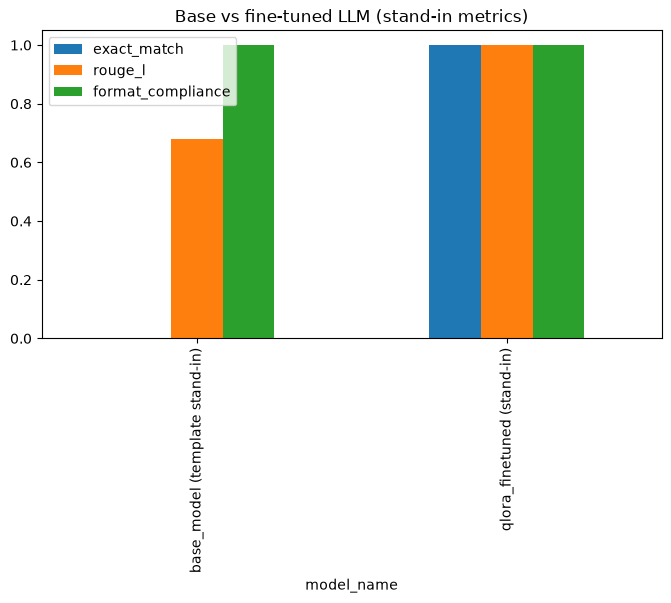

In [6]:
comparison_df[['exact_match', 'rouge_l', 'format_compliance']].plot.bar(
    figsize=(8, 4), title='Base vs fine-tuned LLM (stand-in metrics)'
)

## Real run checklist (GPU required)

```bash
# 1. Fine-tune with QLoRA
python -m src.llm.finetuning \
    --base-model Qwen/Qwen2.5-3B-Instruct \
    --data data/sample/sft_dataset.json \
    --output checkpoints/qlora-support-assistant

# 2. Merge the adapter for ONNX/Triton export
python -m src.llm.merge_adapter \
    --base-model Qwen/Qwen2.5-3B-Instruct \
    --adapter checkpoints/qlora-support-assistant \
    --output checkpoints/merged-support-assistant
```

Then replace the `base_predictions`/`finetuned_predictions` cells above with:

```python
from src.llm.inference import FineTunedLLM

base_llm = FineTunedLLM('Qwen/Qwen2.5-3B-Instruct')
finetuned_llm = FineTunedLLM('Qwen/Qwen2.5-3B-Instruct', adapter_path='checkpoints/qlora-support-assistant')
```

and generate real completions per example with `.generate(prompt).text` using `src.rag.context_builder.build_prompt`.

## Takeaways

- Format compliance (valid JSON matching the required schema) is often the single biggest win from fine-tuning an instruction model on a structured-output task -- track it explicitly, not just text similarity metrics.
- ROUGE-L / Exact Match should be read together with BERTScore on the real run (`compute_bertscore=True`) since paraphrased-but-correct answers score low on lexical-overlap metrics alone.
- Keep a held-out slice of real support tickets (not used in SFT training) for this comparison to avoid overstating fine-tuning gains.